# Two-Means PCA

## References
- [K‑means Clustering via Principal Component Analysis (Chris Ding & Xiaofeng He, ICML 2004)](https://icml.cc/Conferences/2004/proceedings/papers/262.pdf)  

## Problem Definition

We are given a dataset
$$
X = [x_1, \ldots, x_n]^T \in \mathbb{R}^{n \times d},
$$
and we aim to partition it into two disjoint clusters $\Omega_1, \Omega_2$ that minimize the **within-cluster sum of squared errors (SSE)**:

$$
\min_{\Omega_1, \Omega_2} J = \sum_{x_i \in \Omega_1} \|x_i - \mu_1\|_2^2 + \sum_{x_i \in \Omega_2} \|x_i - \mu_2\|_2^2,
$$

where $\mu_j = \frac{1}{|\Omega_j|}\sum_{x_i \in \Omega_j} x_i$ are cluster centroids.

For $k=2$, this problem can be simplified geometrically:
the optimal separating hyperplane must be orthogonal to the line joining $\mu_1$ and $\mu_2$.

---

## Data Normalization

We normalize each feature dimension:

$$
Z = (X - \text{mean}) \oslash \text{std}, \quad Z \in \mathbb{R}^{n \times d},
$$
where “$\oslash$” denotes element-wise division.

Thus, each column of $Z$ has zero mean and unit variance, which is required for Principal Component Analysis (PCA).

---

## Principal Component Projection (PCA)

PCA finds directions $(u_1, u_2, \ldots, u_d)$ that capture maximal variance when projecting the data onto them:
$$
\begin{aligned}
u &= \arg\max_{\|u\|_2 = 1} \operatorname{Var}(Z u) \\
&= \arg\max_{\|u\|_2=1} \frac{1}{n}\|Z u\|_2^2 \quad \because (\mu = 0) \\
&= \arg\max_{\|u\|_2=1} \frac{1}{n} u^T (Z^T Z) u \\
&= \arg\max_{\|u\|_2=1} u^T \Sigma u, \quad \Sigma = \frac{1}{n} Z^T Z.
\end{aligned}
$$
Here, $\Sigma = \frac{1}{n} Z^T Z$ is the sample covariance matrix.

### Rayleigh Quotient and SVD
Let $\Sigma$ be symmetric positive semi-definite. Then, its eigen-decomposition is:
$$
\Sigma = V \Lambda V^T,
$$
where:
- $V = [v_1, \ldots, v_d]$ contains orthonormal eigenvectors,
- $\Lambda = \operatorname{diag}(\lambda_1, \ldots, \lambda_d)$ with $\lambda_1 \ge \lambda_2 \ge \cdots \ge 0$ are eigenvalues.

The Rayleigh quotient states:
$$
\max_{\|u\|_2=1} u^T \Sigma u = \lambda_1,
$$
achieved at $u = v_1$ (the top eigenvector).

Hence, from the SVD of $Z$:
$$Z = U S V^T \\
\implies \Sigma = \frac{1}{n} V S^2 V^T.
$$
Thus, the first principal component $v_1$ is the eigenvector corresponding to the largest singular value $s_1$ (or equivalently, the largest eigenvalue $\lambda_1 = s_1^2$).
Hence the variance along $u = v_1$ is:
$$
\operatorname{Var}(Z u) = \frac{1}{n} \|Z u\|_2^2 = \lambda_1.
$$



---

## One-Dimensional Projection

Project all normalized samples onto the direction $u$:

$$
s_i = z_i^T u \in \mathbb{R} \quad \text{for } i = 1, \ldots, n,
$$

yielding the 1-D representation $s = Z u \in \mathbb{R}^n$.

The $s_i$’s are then **sorted**, giving an ordered view of the data along the direction of maximum spread.

This transforms the clustering problem from $\mathbb{R}^d$ to $\mathbb{R}^1$:

$$
\min_{\Omega_1, \Omega_2}
\sum_{s_i \in \Omega_1} (s_i - \mu_1)^2 +
\sum_{s_i \in \Omega_2} (s_i - \mu_2)^2.
$$

---

## Exact 1-D Split via Prefix-Sum SSE Minimization

Let the sorted data be $s_{(1)} \le s_{(2)} \le \cdots \le s_{(n)}$.
For any possible threshold index $k$, define:

$$
\Omega_1(k) = \{s_{(1)}, \ldots, s_{(k)}\}, \qquad
\Omega_2(k) = \{s_{(k+1)}, \ldots, s_{(n)}\}.
$$

We compute the exact within-cluster SSE for each split point $k$ using prefix sums.

### SSE Identity

For any subset $S = \{s_i\}_{i=1}^m$, the within-cluster sum of squares satisfies

$$
\sum_{s_i \in S} (s_i - \bar{s}_S)^2
= \sum_{s_i \in S} s_i^2 - \frac{1}{m}\left(\sum_{s_i \in S} s_i\right)^2.
$$

**Proof:**
$$
\begin{aligned}
\sum (s_i - \mu_S)^2
&= \sum s_i^2 - 2\mu_S \sum s_i + \sum \mu_S^2 \\
&= \sum s_i^2 - 2\mu_S (m \mu_S) + m\mu_S^2 \quad \because \sum s_i = m \mu_S \\
&= \sum s_i^2 - m \mu_S^2 \\
&= \sum s_i^2 - \frac{1}{m} \left(\sum s_i\right)^2.
\end{aligned}
$$

Thus, with prefix sums
$$
p_k = \sum_{i=1}^k s_{i}, \qquad
q_k = \sum_{i=1}^k s_{i}^2,
$$
we can compute SSE for each split $k$ in $O(1)$ time:
$$
\begin{aligned}
SSE(k) &= \sum_{i=1}^k (s_{(i)} - \mu_1)^2 + \sum_{i=k+1}^n (s_{(i)} - \mu_2)^2 \\
&= \sum_{i=1}^k s_{(i)}^2 - \frac{1}{k} \left(\sum_{i=1}^k s_{(i)}\right)^2 +
\sum_{i=k+1}^n s_{(i)}^2 - \frac{1}{n-k} \left(\sum_{i=k+1}^n s_{(i)}\right)^2 \\
&= \bigg(q_k - \frac{1}{k} p_k^2 \bigg) + \bigg((q_n - q_k) - \frac{1}{n-k} (p_n - p_k)^2\bigg).
\end{aligned}
$$

---


## Algorithmic Summary

| Step      | Operation                                 | Complexity                  |
| --------- | ----------------------------------------- | --------------------------- |
| 1         | Normalize $X$                             | $O(nd)$                     |
| 2         | Compute top singular vector ($u$) via SVD | $O(nd^2)$                   |
| 3         | Project: $s = Zu$                         | $O(nd)$                     |
| 4         | Sort $s$                                  | $O(n \log n)$               |
| 5         | Compute prefix sums and SSE scan          | $O(n)$                      |
| **Total** |                                           | $\mathbf{O(nd^2 + n \log n)}$ |

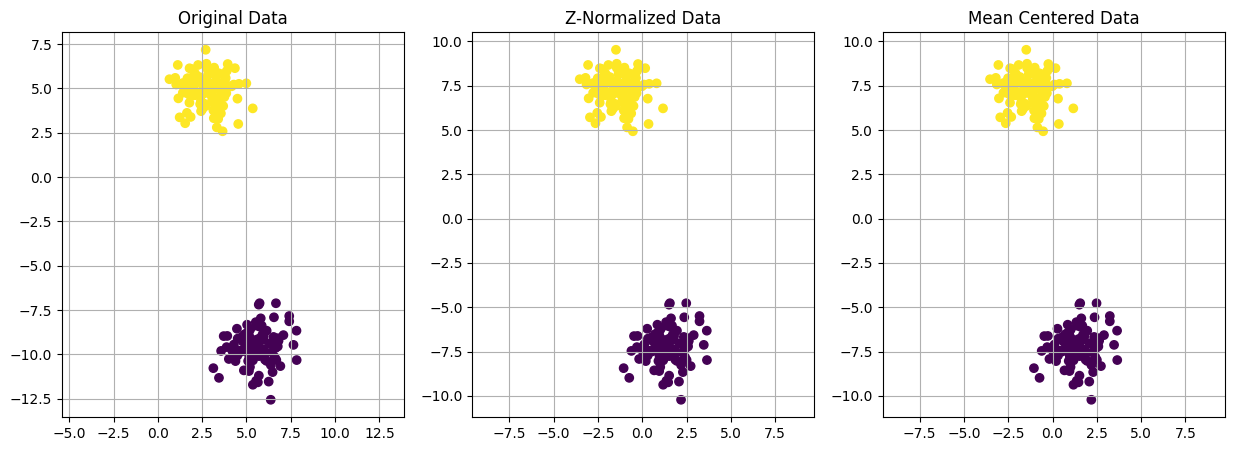

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import (make_blobs, make_circles, make_classification,
                              make_moons)

SEED = 10
np.random.seed(SEED)

# NX2 random points for 2 clusters
N_CLUSTERS = 2
N = 200
# x, y = make_moons(n_samples=N, noise=0.1, random_state=SEED)
# x, y = make_circles(n_samples=N, noise=0.1, random_state=SEED)
# x, y = make_classification(
#     n_samples=N,
#     n_features=2,
#     n_redundant=0,
#     n_informative=2,
#     n_clusters_per_class=1,
#     n_classes=N_CLUSTERS,
#     random_state=SEED,
# )
x, y = make_blobs(n_samples=N, centers=N_CLUSTERS, cluster_std=1.0, random_state=SEED)

# Z-normalize
mean = np.mean(x, axis=0)
std = np.std(x, axis=0)
std = np.where(std == 0, 1, std)  # Prevent division by zero
Z = x - mean  # / std
ZeroMeanData = x - mean

x_lims_X = (np.min(x[:, 0]) - 1, np.max(x[:, 0]) + 1)
y_lims_X = (np.min(x[:, 1]) - 1, np.max(x[:, 1]) + 1)
x_lims_Z = (np.min(Z[:, 0]) - 1, np.max(Z[:, 0]) + 1)
y_lims_Z = (np.min(Z[:, 1]) - 1, np.max(Z[:, 1]) + 1)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.title("Original Data")
plt.scatter(x[:, 0], x[:, 1], c=y)
plt.axis("equal")
plt.grid()

plt.subplot(1, 3, 2)
plt.title("Z-Normalized Data")
plt.scatter(Z[:, 0], Z[:, 1], c=y)
plt.axis("equal")
plt.grid()

plt.subplot(1, 3, 3)
plt.title("Mean Centered Data")
plt.scatter(ZeroMeanData[:, 0], ZeroMeanData[:, 1], c=y)
plt.axis("equal")
plt.grid()
plt.show()

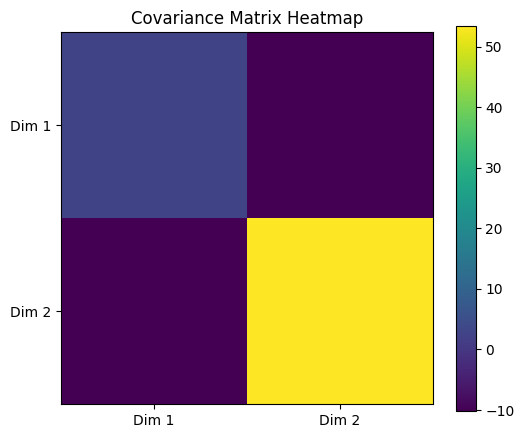

array([[  2.87975538, -10.13669238],
       [-10.13669238,  53.46264249]])

In [ ]:
# Compute covariance matrix
sigma = (1 / N) * (Z.T @ Z)

# Plot covariance matrix as heatmap
plt.figure(figsize=(6, 5))
plt.imshow(sigma, cmap="viridis", interpolation="nearest")
plt.colorbar()
plt.title("Covariance Matrix Heatmap")
plt.xticks(range(sigma.shape[0]), [f"Dim {i+1}" for i in range(sigma.shape[0])])
plt.yticks(range(sigma.shape[1]), [f"Dim {i+1}" for i in range(sigma.shape[1])])
plt.show()

display(sigma)

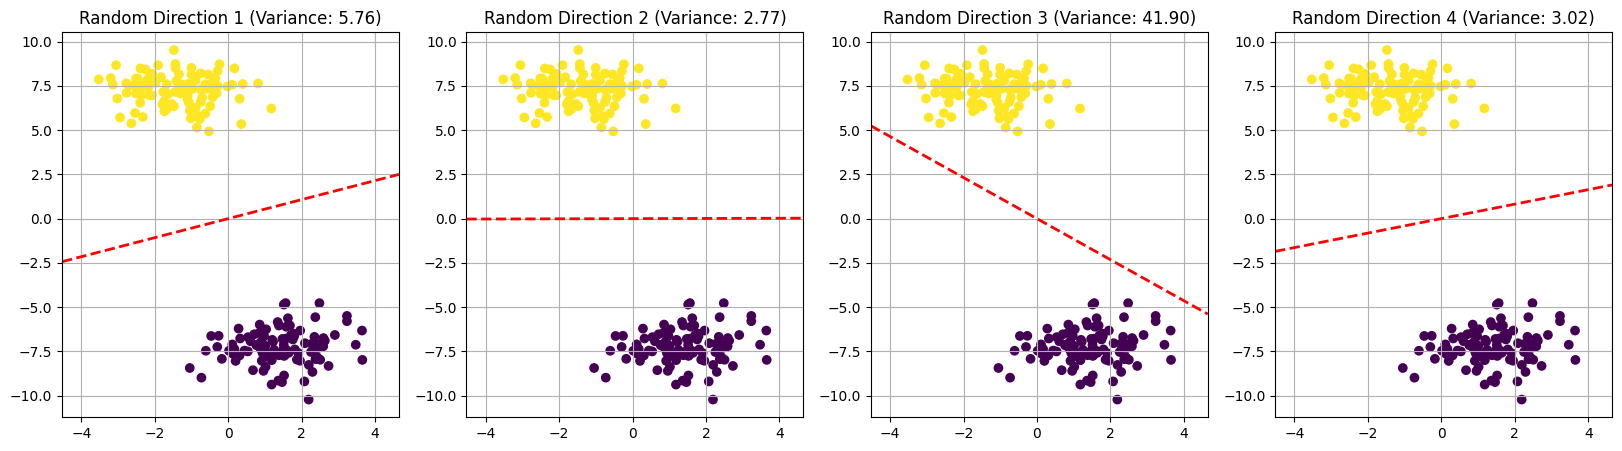

In [ ]:
# PCA finds direction that captures maximum variance, when data is projected onto it
# Let us try random vectors for U before selecting the best one
num_random_directions = 4
random_directions = np.random.randn(num_random_directions, 2)
random_directions /= np.linalg.norm(random_directions, axis=1, keepdims=True)

plt.figure(figsize=(num_random_directions * 5, 5))
for i in range(num_random_directions):
    # Compute projections
    S = Z @ random_directions[i]
    variance = np.var(S)

    plt.subplot(1, num_random_directions, i + 1)
    plt.title(f"Random Direction {i + 1} (Variance: {variance:.2f})")
    plt.scatter(Z[:, 0], Z[:, 1], c=y)

    # Plot the random direction line
    direction = random_directions[i]
    line_x = np.array(x_lims_Z)
    line_y = (direction[1] / direction[0]) * (line_x - 0) + 0  # Line through origin
    plt.plot(line_x, line_y, "r--", linewidth=2)
    plt.xlim(x_lims_Z)
    plt.ylim(y_lims_Z)
    plt.grid()
plt.show()

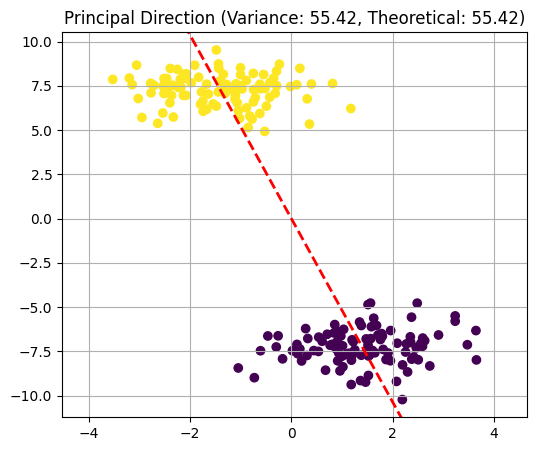

Principal Direction: [-0.18944405  0.98189152]


In [ ]:
# Let us now compute the optimal direction using SVD
U, S, VT = np.linalg.svd(Z)
principal_direction = VT[0]  # First principal component
sigma_max = S[0]
theoretical_variance = (sigma_max**2) / N

# Compute projections onto principal direction
S = Z @ principal_direction
variance = np.var(S)
plt.figure(figsize=(6, 5))
plt.title(
    f"Principal Direction (Variance: {variance:.2f}, Theoretical: {theoretical_variance:.2f})"
)
plt.scatter(Z[:, 0], Z[:, 1], c=y)

# Plot the principal direction line
line_x = np.array(x_lims_Z)
line_y = (principal_direction[1] / principal_direction[0]) * (
    line_x - 0
) + 0  # Line through origin
plt.plot(line_x, line_y, "r--", linewidth=2)
plt.xlim(x_lims_Z)
plt.ylim(y_lims_Z)
plt.grid()
plt.show()
print(f"Principal Direction: {principal_direction}")

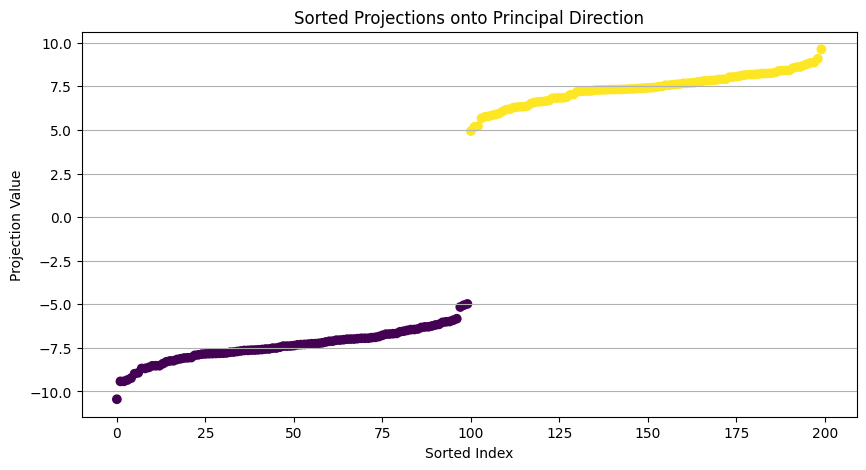

In [ ]:
# Sort projections
sorted_indices = np.argsort(S)

# plot sorted projections
plt.figure(figsize=(10, 5))
plt.title("Sorted Projections onto Principal Direction")
plt.scatter(range(N), S[sorted_indices], c=y[sorted_indices])
plt.xlabel("Sorted Index")
plt.ylabel("Projection Value")
plt.grid(axis="y")
plt.show()

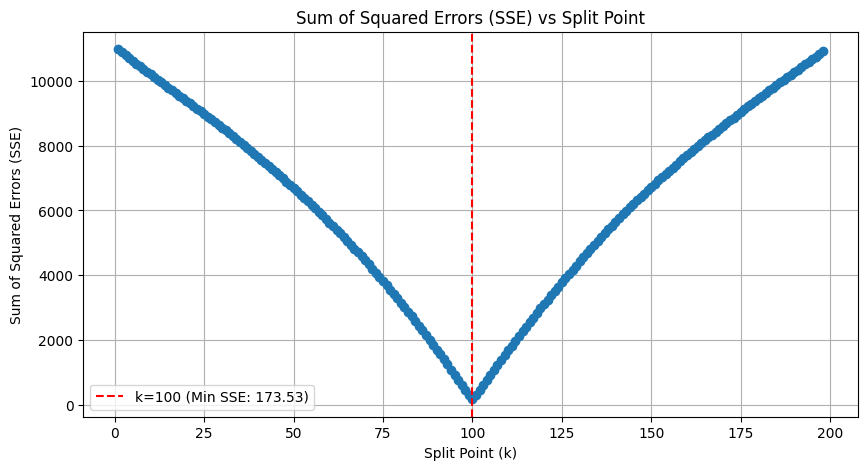

Optimal Split Point (k): 100, Minimum SSE: 173.53
Optimal split point using prefix sums: k=100, Min SSE=173.527768


In [ ]:
# 1D SSE problem: minimize sum of squared errors between the two clusters by plotting the SSEs vs different values of k
sse_values = []
k = range(1, len(S) - 1)

for split_point in k:
    cluster_1 = S[sorted_indices][:split_point]
    cluster_2 = S[sorted_indices][split_point:]

    mean_1 = np.mean(cluster_1)
    mean_2 = np.mean(cluster_2)

    sse_1 = np.sum((cluster_1 - mean_1) ** 2)
    sse_2 = np.sum((cluster_2 - mean_2) ** 2)

    total_sse = sse_1 + sse_2
    sse_values.append(total_sse)
min_sse_index = np.argmin(sse_values)
optimal_split = k[min_sse_index]

plt.figure(figsize=(10, 5))
plt.title("Sum of Squared Errors (SSE) vs Split Point")
plt.plot(k, sse_values, marker="o")
plt.axvline(
    optimal_split,
    color="r",
    linestyle="--",
    label=f"k={optimal_split} (Min SSE: {sse_values[min_sse_index]:.2f})",
)
plt.xlabel("Split Point (k)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.legend()
plt.grid()
plt.show()
print(
    f"Optimal Split Point (k): {optimal_split}, Minimum SSE: {sse_values[min_sse_index]:.2f}"
)


# Calculate the optimal split point using prefix sums for efficiency
S_sorted = S[sorted_indices]
pref_sum = np.cumsum(S_sorted)  # (n,)
pref_sq = np.cumsum(S_sorted**2)  # (n,)
total_sum = pref_sum[-1]
total_sq = pref_sq[-1]


best_k = 1
best_sse = np.inf
# Scan all split points 1..n-1
for k in range(1, N):
    left_sum = pref_sum[k - 1]
    left_sq = pref_sq[k - 1]
    right_sum = total_sum - left_sum
    right_sq = total_sq - left_sq

    # SSE = sum(x^2) - sum(x)^2/n for each cluster
    sse_left = left_sq - (left_sum**2) / k
    rn = N - k
    sse_right = right_sq - (right_sum**2) / rn
    sse = sse_left + sse_right
    if sse < best_sse:
        best_sse = sse
        best_k = k

print(f"Optimal split point using prefix sums: k={best_k}, Min SSE={best_sse:2f}")

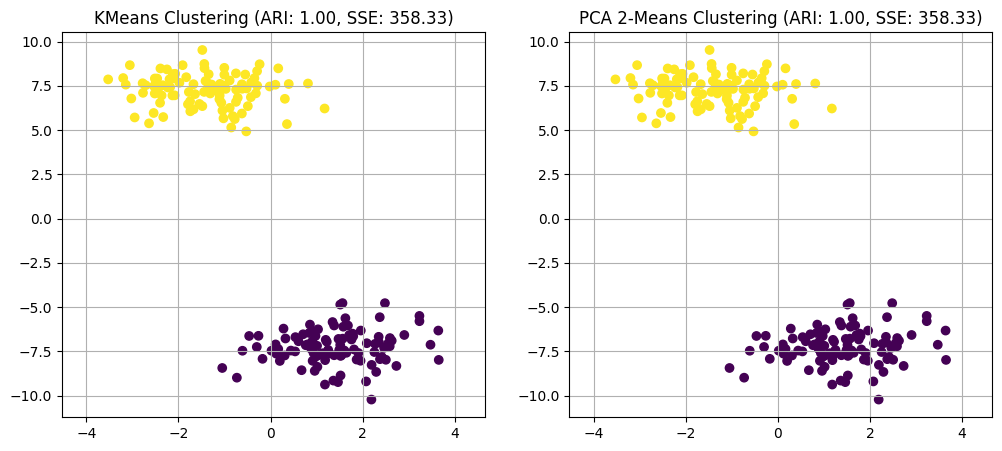

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Label clusters based on optimal split
cluster_labels = np.zeros(N)
cluster_labels[sorted_indices[:optimal_split]] = 0
cluster_labels[sorted_indices[optimal_split:]] = 1

# Perform KMeans clustering for comparison
kmeans = KMeans(n_clusters=2, random_state=SEED)
kmeans.fit(Z)
kmeans_labels = kmeans.labels_

# Compute Adjusted Rand Index for both methods
ari_optimal_split = adjusted_rand_score(y, cluster_labels)
ari_kmeans = adjusted_rand_score(y, kmeans_labels)


# Compute SSE for both methods
def compute_sse(data, labels):
    sse = 0
    for cluster in np.unique(labels):
        cluster_points = data[labels == cluster]
        cluster_mean = np.mean(cluster_points, axis=0)
        sse += np.sum((cluster_points - cluster_mean) ** 2)
    return sse


sse_optimal_split = compute_sse(Z, cluster_labels)
sse_kmeans = compute_sse(Z, kmeans_labels)

# Plot comparison of clustering results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.title(f"KMeans Clustering (ARI: {ari_kmeans:.2f}, SSE: {sse_kmeans:.2f})")
plt.scatter(Z[:, 0], Z[:, 1], c=kmeans_labels)
plt.xlim(x_lims_Z)
plt.ylim(y_lims_Z)
plt.grid()

plt.subplot(1, 2, 2)
plt.title(
    f"PCA 2-Means Clustering (ARI: {ari_optimal_split:.2f}, SSE: {sse_optimal_split:.2f})"
)
plt.scatter(Z[:, 0], Z[:, 1], c=cluster_labels)
plt.xlim(x_lims_Z)
plt.ylim(y_lims_Z)
plt.grid()
plt.show()

## Randomized QR

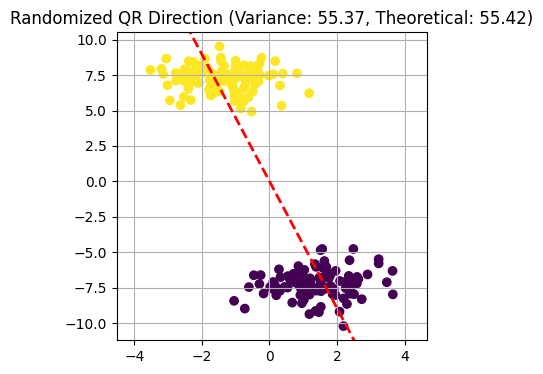

Randomized QR Direction: [-0.21780275  0.97599281], Principal Direction: [-0.18944405  0.98189152]


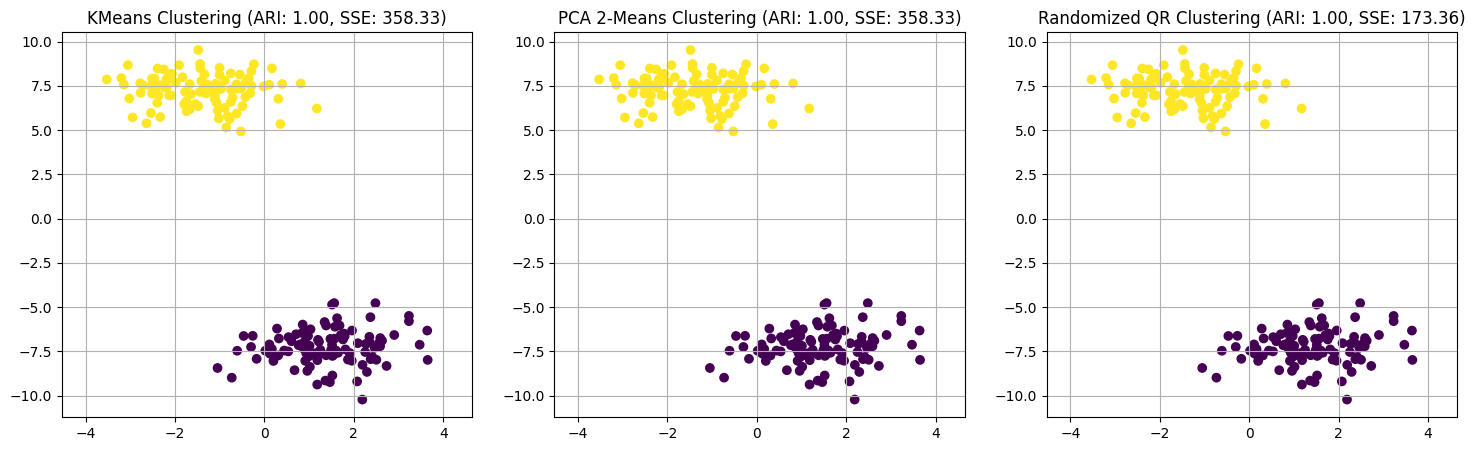

In [ ]:
def randomized_qr(X: np.ndarray, ell: int = 8, power_iterations: int = 1) -> np.ndarray:
    XT = X.T
    D, N = XT.shape
    omega = np.random.randn(N, ell)

    e = np.ones((1, N))
    mu = (1 / N) * (XT @ e.T)
    X0 = XT - mu @ e

    Y = X0 @ omega
    Q, _ = np.linalg.qr(Y)
    for _ in range(power_iterations):
        Y = X0 @ (X0.T @ Q)
        Q, _ = np.linalg.qr(Y)
    return Q[:, 0]


ell = 20
power_iterations = 1

q = randomized_qr(Z, ell=ell, power_iterations=power_iterations)
# COmpute projections onto q
S_q = Z @ q
variance_q = np.var(S_q)
plt.figure(figsize=(4, 4))
plt.title(
    f"Randomized QR Direction (Variance: {variance_q:.2f}, Theoretical: {theoretical_variance:.2f})"
)
plt.scatter(Z[:, 0], Z[:, 1], c=y)

# Plot the randomized QR direction line
line_x = np.array(x_lims_Z)
line_y = (q[1] / q[0]) * (line_x - 0) + 0  # Line through origin
plt.plot(line_x, line_y, "r--", linewidth=2)
plt.xlim(x_lims_Z)
plt.ylim(y_lims_Z)
plt.grid()
plt.show()
print(f"Randomized QR Direction: {q}, Principal Direction: {principal_direction}")

# Sort projections
sorted_indices_q = np.argsort(S_q)

sse_values_q = []
k = range(1, len(S_q) - 1)
for split_point in k:
    cluster_1 = S_q[sorted_indices_q][:split_point]
    cluster_2 = S_q[sorted_indices_q][split_point:]

    mean_1 = np.mean(cluster_1)
    mean_2 = np.mean(cluster_2)

    sse_1 = np.sum((cluster_1 - mean_1) ** 2)
    sse_2 = np.sum((cluster_2 - mean_2) ** 2)

    total_sse = sse_1 + sse_2
    sse_values_q.append(total_sse)
min_sse_index_q = np.argmin(sse_values_q)
optimal_split_q = k[min_sse_index_q]

cluster_labels_q = np.zeros(N)
cluster_labels_q[sorted_indices_q[:optimal_split_q]] = 0
cluster_labels_q[sorted_indices_q[optimal_split_q:]] = 1

ari_randomized_qr = adjusted_rand_score(y, cluster_labels_q)


# Plot comparison of clustering results
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)
plt.title(f"KMeans Clustering (ARI: {ari_kmeans:.2f}, SSE: {sse_kmeans:.2f})")
plt.scatter(Z[:, 0], Z[:, 1], c=kmeans_labels)
plt.xlim(x_lims_Z)
plt.ylim(y_lims_Z)
plt.grid()

plt.subplot(1, 3, 2)
plt.title(
    f"PCA 2-Means Clustering (ARI: {ari_optimal_split:.2f}, SSE: {sse_optimal_split:.2f})"
)
plt.scatter(Z[:, 0], Z[:, 1], c=cluster_labels)
plt.xlim(x_lims_Z)
plt.ylim(y_lims_Z)
plt.grid()

plt.subplot(1, 3, 3)
plt.title(
    f"Randomized QR Clustering (ARI: {ari_randomized_qr:.2f}, SSE: {sse_values_q[min_sse_index_q]:.2f})"
)
plt.scatter(Z[:, 0], Z[:, 1], c=cluster_labels_q)
plt.xlim(x_lims_Z)
plt.ylim(y_lims_Z)
plt.grid()
plt.show()